In [1]:
# 10. Environment and pre-experiment prediction confirmation.
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['MKL_NUM_THREADS'] = '4'
from pathlib import Path
import importlib.metadata
import json
import platform
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support
import joblib
from preprocessing import load_imdb, inspect_dataset, clean_official_splits, tokenize
from rnn_cell import SimpleRNNCell
from sequence_utils import (seed_everything, build_vocabulary, encode, collate_reviews,
    SequenceClassifier, make_loader, train_run, load_run, evaluate, metric_record,
    predict_token_lists, retained_table, sha256)

BASE = Path.cwd()
assert (BASE / 'rnn_cell.py').is_file(), 'Run with the working directory set to lab05/'
OUT = BASE / 'outputs'
OUT.mkdir(exist_ok=True)
confirmation = json.loads((BASE / 'prediction_confirmation.json').read_text(encoding='utf-8'))
assert confirmation['completed_before_training'] is True
CONFIG = dict(seed=42, embedding_dim=64, hidden_size=64, batch_size=128,
              learning_rate=0.001, epochs=6, clip_grad_norm=1.0)
MAIN_LENGTH = 100
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(4)
seed_everything(CONFIG['seed'])
pd.set_option('display.max_columns', 25)
pd.set_option('display.max_colwidth', 120)
print('Device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else platform.processor())
print('Prediction completion:', confirmation)
print('Fixed configuration:', CONFIG)

runs, histories, prediction_tables, result_records = {}, [], {}, {}
main_names = ['tfidf_lr','rnn_100','lstm_100','gru_100']

def record_test_evaluation(record):
    name = record['model']
    start = time.perf_counter()
    if name == 'tfidf_lr':
        probabilities = baseline.predict_proba(vectorizer.transform(test.text))[:,1]
    else:
        model = load_run(record, DEVICE)
        _, probabilities, labels = evaluate(model,
            make_loader(test,vocab,record['max_length'],CONFIG['batch_size']),DEVICE)
        assert np.array_equal(labels,test.label.to_numpy())
        del model
    inference_seconds = time.perf_counter()-start
    output = test[['sample_id','text','label']].rename(columns={'label':'true_label'}).copy()
    output['positive_probability'] = probabilities
    output['predicted_label'] = (probabilities>=.5).astype(int)
    output['correct'] = output.true_label.eq(output.predicted_label)
    output['original_tokens'] = test.tokens.map(len)
    output['retained_tokens'] = (output.original_tokens if name=='tfidf_lr'
        else output.original_tokens.clip(upper=record['max_length']))
    prediction_tables[name] = output
    output.to_csv(OUT/f'predictions_{name}.csv',index=False)
    result_records[name] = dict(**record,evaluation_split='test',positive_label=1,threshold=.5,
        train_samples=len(train),validation_samples=len(validation),test_samples=len(test),
        inference_seconds=inference_seconds,**metric_record(test.label,probabilities))
    return result_records[name]

def order_diagnostics(names):
    pairs = [('dog bites man','man bites dog'),
        ('this movie is good','this movie is not good'),
        ('good not bad','bad not good'),
        ('i expected bad but it was good','i expected good but it was bad')]
    order_rows, ablation_rows = [], []
    original_tokens = [tokens[:MAIN_LENGTH] for tokens in test.tokens]
    rng = np.random.default_rng(2026)
    shuffled_tokens = [list(rng.permutation(tokens)) for tokens in original_tokens]
    for name in names:
        model = None if name=='tfidf_lr' else load_run(runs[name],DEVICE)
        for pair_index,(a,b) in enumerate(pairs):
            if name=='tfidf_lr':
                x = vectorizer.transform([a,b])
                difference=x[0]-x[1]
                probs=baseline.predict_proba(x)[:,1]
                delta=float(np.sqrt(difference.multiply(difference).sum()))
            else:
                items=[(encode(tokenize(t),vocab,MAIN_LENGTH),0.) for t in [a,b]]
                ids,lengths,_=collate_reviews(items)
                with torch.inference_mode():
                    logits,hidden=model(ids.to(DEVICE),lengths,return_hidden=True)
                    probs=torch.sigmoid(logits).cpu().numpy()
                    delta=float(torch.linalg.vector_norm(hidden[0]-hidden[1]).cpu())
            order_rows.append(dict(pair=pair_index,model=name,text_a=a,text_b=b,
                probability_a=probs[0],probability_b=probs[1],
                absolute_probability_delta=abs(probs[0]-probs[1]),vector_l2_delta=delta))
        if name=='tfidf_lr':
            original=baseline.predict_proba(vectorizer.transform([' '.join(t) for t in original_tokens]))[:,1]
            shuffled=baseline.predict_proba(vectorizer.transform([' '.join(t) for t in shuffled_tokens]))[:,1]
        else:
            original=predict_token_lists(model,original_tokens,vocab,MAIN_LENGTH,DEVICE)
            shuffled=predict_token_lists(model,shuffled_tokens,vocab,MAIN_LENGTH,DEVICE)
        ablation_rows.append(dict(model=name,split='test',samples=len(test),retained_prefix_tokens=MAIN_LENGTH,
            original_f1=metric_record(test.label,original)['f1'],
            shuffled_f1=metric_record(test.label,shuffled)['f1'],
            mean_absolute_probability_delta=float(np.mean(np.abs(original-shuffled))),
            changed_class_count=int(((original>=.5)!=(shuffled>=.5)).sum())))
        del model
    return pd.DataFrame(order_rows),pd.DataFrame(ablation_rows)

Device: cuda NVIDIA GeForce RTX 3050 Laptop GPU
Prediction completion: {'completed_before_training': True, 'source': 'User explicitly confirmed all five W5 predictions completed before training in this chat', 'client_date': '2026-10-16', 'timezone': 'Asia/Saigon'}
Fixed configuration: {'seed': 42, 'embedding_dim': 64, 'hidden_size': 64, 'batch_size': 128, 'learning_rate': 0.001, 'epochs': 6, 'clip_grad_norm': 1.0}


,samples,classes,missing_text,blank_text,missing_labels,invalid_labels,raw_duplicate_extra_rows,token_duplicate_extra_rows,token_duplicate_groups
0,50000,2,0,0,0,0,418,424,412


,official_split,label,count,class,percentage
0,test,0,12500,negative,50.0
1,test,1,12500,positive,50.0
2,train,0,12500,negative,50.0
3,train,1,12500,positive,50.0


,samples,minimum,median,mean,maximum
official_split,,,,,
test,25000,6,172.0,228.63000,2247
train,25000,10,175.0,233.91156,2477


,0.10,0.25,0.50,0.75,0.90,0.95,0.99
official_split,,,,,,,
test,89.0,126.0,172.0,277.0,443.0,582.0,897.0
train,90.0,127.0,175.0,284.0,458.0,599.0,912.0


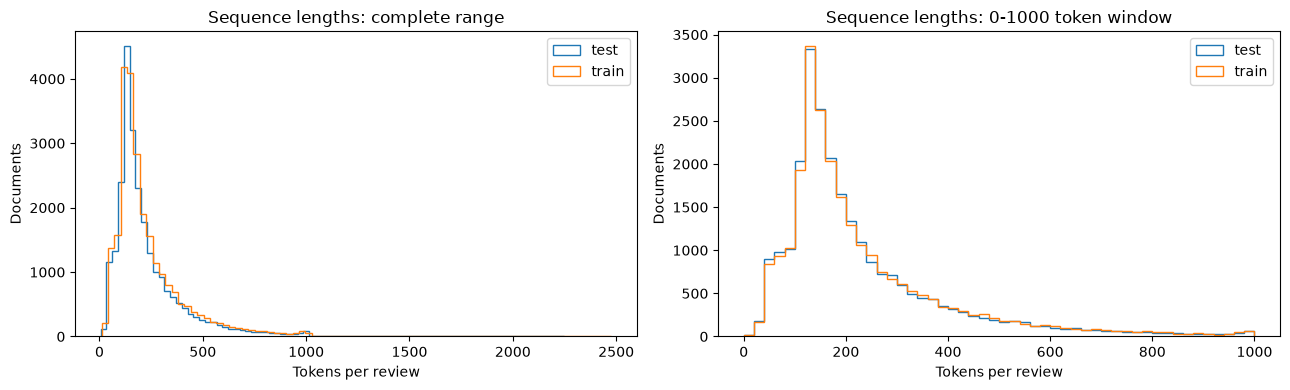

In [2]:
# 11. Raw dataset inspection and sequence-length histogram (no fitting).
raw = load_imdb(BASE / 'data')
audit, distribution, raw_lengths = inspect_dataset(raw)
length_summary = raw_lengths.groupby('official_split').tokens.agg(
    samples='count', minimum='min', median='median', mean='mean', maximum='max')
quantiles = raw_lengths.groupby('official_split').tokens.quantile([.1,.25,.5,.75,.9,.95,.99]).unstack()
audit.to_csv(OUT / 'dataset_audit_raw.csv', index=False)
distribution.to_csv(OUT / 'class_distribution_raw.csv', index=False)
raw_lengths.to_csv(OUT / 'document_lengths_raw.csv', index=False)
length_summary.to_csv(OUT / 'length_summary_raw.csv')
quantiles.to_csv(OUT / 'length_quantiles_raw.csv')
display(audit, distribution, length_summary, quantiles)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for split, values in raw_lengths.groupby('official_split'):
    axes[0].hist(values.tokens, bins=80, histtype='step', label=split)
    axes[1].hist(values.tokens, bins=np.arange(0,1001,20), histtype='step', label=split)
axes[0].set(title='Sequence lengths: complete range', xlabel='Tokens per review', ylabel='Documents')
axes[1].set(title='Sequence lengths: 0-1000 token window', xlabel='Tokens per review', ylabel='Documents')
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'sequence_length_histogram.png', dpi=160)
plt.show()

In [3]:
# 12. Clean splits, reuse LAB04 manifest, train-only vocabulary, IDs and padding.
cleaned, cleaning_audit = clean_official_splits(raw)
manifest = pd.read_csv(BASE / 'data' / 'lab04_split_manifest.csv')
joined = manifest.merge(cleaned, on='sample_id', suffixes=('_manifest',''), validate='one_to_one')
assert len(joined) == len(manifest) == len(cleaned)
assert joined.document_key_manifest.eq(joined.document_key).all()
assert joined.label_manifest.eq(joined.label).all()
frames = {split: joined.loc[joined.split.eq(split)].reset_index(drop=True)
          for split in ['train','validation','test']}
train, validation, test = [frames[split] for split in ['train','validation','test']]
overlaps = []
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    overlap = len(set(frames[a].document_key) & set(frames[b].document_key))
    assert overlap == 0
    overlaps.append(dict(split_a=a, split_b=b, overlapping_document_keys=overlap))
vocab = build_vocabulary(train.tokens, max_size=20000, min_count=2)
(OUT / 'vocabulary.json').write_text(json.dumps(vocab, ensure_ascii=False), encoding='utf-8')
manifest.to_csv(OUT / 'split_manifest.csv', index=False)
cleaning_audit.to_csv(OUT / 'cleaning_audit.csv', index=False)
pd.DataFrame(overlaps).to_csv(OUT / 'split_overlap_audit.csv', index=False)
split_distribution = joined.groupby(['split','label']).size().rename('samples').reset_index()
split_distribution.to_csv(OUT / 'split_distribution.csv', index=False)
coverage = []
for split, frame in frames.items():
    count = sum(len(tokens) for tokens in frame.tokens)
    unknown = sum(token not in vocab for tokens in frame.tokens for token in tokens)
    coverage.append(dict(split=split, samples=len(frame), tokens=count,
                         unknown_tokens=unknown, unknown_percent=100*unknown/count))
pd.DataFrame(coverage).to_csv(OUT / 'vocabulary_coverage.csv', index=False)
example_tokens = tokenize('I really like this movie')
example_ids = encode(example_tokens, vocab, 8)
padded_example = example_ids + [0] * (8-len(example_ids))
display(cleaning_audit, split_distribution, pd.DataFrame(overlaps), pd.DataFrame(coverage))
print('Vocabulary size including PAD/UNK:', len(vocab))
print('Tokens:', example_tokens, 'IDs:', example_ids, 'padded to 8:', padded_example)

,official_split,original,invalid_or_empty_removed,conflicting_label_groups,conflicting_label_rows_removed,duplicate_extra_rows_removed,cross_split_rows_removed,retained
0,train,25000,0,0,0,99,0,24901
1,test,25000,0,0,0,202,123,24675


,split,label,samples
0,test,0,12264
1,test,1,12411
2,train,0,9944
3,train,1,9976
4,validation,0,2487
5,validation,1,2494


,split_a,split_b,overlapping_document_keys
0,train,validation,0
1,train,test,0
2,validation,test,0


,split,samples,tokens,unknown_tokens,unknown_percent
0,train,19920,4661801,118433,2.540499
1,validation,4981,1168983,34690,2.967537
2,test,24675,5645119,186631,3.306060


Vocabulary size including PAD/UNK: 20000
Tokens: ['i', 'really', 'like', 'this', 'movie'] IDs: [10, 63, 37, 11, 17] padded to 8: [10, 63, 37, 11, 17, 0, 0, 0]


In [4]:
# 13. Experiment 2: padding/truncation at 50, 100 and 200 tokens (fixed RNN).
retention = retained_table(frames)
retention.to_csv(OUT/'tokens_retained.csv',index=False)
display(retention)
for length in [50,100,200]:
    record, history = train_run('RNN',length,train,validation,vocab,CONFIG,DEVICE,OUT)
    runs[record['model']] = record
    histories.extend(history)
    record_test_evaluation(record)
padding_results = pd.DataFrame([result_records[f'rnn_{length}'] for length in [50,100,200]])
padding_results = padding_results.merge(retention.loc[retention.split.eq('test')],
    on='max_length',validate='one_to_one').sort_values('max_length')
padding_results.to_csv(OUT/'padding_truncation_results.csv',index=False)
display(padding_results[['model','evaluation_split','max_length','percent_tokens_retained',
    'training_time_seconds','accuracy','f1','validation_loss','validation_f1']])

,split,max_length,documents,total_tokens,retained_tokens,percent_tokens_retained,percent_documents_truncated,percent_documents_padded,percent_padding_at_fixed_length
0,train,30,19920,4661801,597320,12.813074,99.784137,0.200803,0.046854
1,train,50,19920,4661801,991912,21.277442,97.575301,2.264056,0.410442
2,train,100,19920,4661801,1917796,41.138521,87.911647,11.887550,3.725100
3,train,200,19920,4661801,3175500,68.117451,41.681727,58.012048,20.293675
4,validation,30,4981,1168983,149355,12.776490,99.779161,0.180687,0.050191
5,validation,50,4981,1168983,248142,21.227169,97.972295,1.927324,0.364585
6,validation,100,4981,1168983,480203,41.078698,88.114836,11.704477,3.593054
7,validation,200,4981,1168983,795587,68.058047,41.236699,58.462156,20.137824
8,test,30,24675,5645119,739808,13.105268,99.752786,0.222898,0.059710
9,test,50,24675,5645119,1228164,21.756211,97.442756,2.362715,0.452766


rnn_50: epoch 1/6 train=0.6805 val=0.6552 val_f1=0.5816 train_s=6.0


rnn_50: epoch 2/6 train=0.5178 val=0.5241 val_f1=0.7442 train_s=3.9


rnn_50: epoch 3/6 train=0.3766 val=0.5723 val_f1=0.7471 train_s=3.2


rnn_50: epoch 4/6 train=0.2895 val=0.5745 val_f1=0.7653 train_s=2.3


...

rnn_200: epoch 3/6 train=0.3727 val=0.4816 val_f1=0.7662 train_s=8.5


rnn_200: epoch 4/6 train=0.3137 val=0.4876 val_f1=0.7996 train_s=8.8


rnn_200: epoch 5/6 train=0.2480 val=0.5138 val_f1=0.7944 train_s=8.3


rnn_200: epoch 6/6 train=0.1843 val=0.5784 val_f1=0.7672 train_s=9.9


,model,evaluation_split,max_length,percent_tokens_retained,training_time_seconds,accuracy,f1,validation_loss,validation_f1
0,rnn_50,test,50,21.756211,21.396361,0.734306,0.722298,0.524061,0.744167
1,rnn_100,test,100,41.987211,27.971592,0.781398,0.770077,0.472643,0.790746
2,rnn_200,test,200,69.235387,47.877656,0.785167,0.760861,0.481550,0.766185


In [5]:
# 14. NumPy RNN cell vs torch.nn.RNNCell; independent inputs, not the handwritten exercise.
rng = np.random.default_rng(123)
custom = SimpleRNNCell(input_size=3, hidden_size=4, seed=123)
custom.b_h = rng.normal(0, 0.1, 4)
reference = torch.nn.RNNCell(3, 4, nonlinearity='tanh').double()
with torch.no_grad():
    reference.weight_ih.copy_(torch.from_numpy(custom.W_xh))
    reference.weight_hh.copy_(torch.from_numpy(custom.W_hh))
    reference.bias_ih.copy_(torch.from_numpy(custom.b_h))
    reference.bias_hh.zero_()
cell_tests = []
for batch in [1, 2]:
    x = rng.normal(size=(batch,3))
    h = rng.normal(size=(batch,4))
    actual = custom.forward(x,h)
    expected = reference(torch.from_numpy(x),torch.from_numpy(h)).detach().numpy()
    np.testing.assert_allclose(actual, expected, rtol=1e-12, atol=1e-12)
    cell_tests.append(dict(batch=batch, input_size=3, hidden_size=4,
                           maximum_absolute_error=float(np.max(np.abs(actual-expected))), passed=True))
    print('Input:', x, '\nPrevious hidden:', h, '\nNumPy:', actual, '\nPyTorch:', expected)
unbatched = custom.forward(x[0], h[0])
np.testing.assert_allclose(unbatched, actual[0], rtol=1e-12, atol=1e-12)
pd.DataFrame(cell_tests).to_csv(OUT / 'rnn_cell_verification.csv', index=False)
display(pd.DataFrame(cell_tests))

Input: [[ 0.9202309   0.57710379 -0.63646365]] 
Previous hidden: [[ 0.54195222 -0.31659545 -0.32238912  0.09716732]] 
NumPy: [[ 0.18823554 -0.45505805  0.15372752  0.50945041]] 
PyTorch: [[ 0.18823554 -0.45505805  0.15372752  0.50945041]]
Input: [[-1.52593041  1.1921661  -0.67108968]
 [ 1.00026942  0.13632112  1.53203308]] 
Previous hidden: [[-0.65996941 -0.31179486  0.33776913 -2.2074711 ]
 [ 0.82792144  1.54163039  1.12680679  0.75476964]] 
NumPy: [[-0.78236777 -0.28077117 -0.71638135 -0.49521581]
 [-0.20545004  0.3564333   0.32238974 -0.69055274]] 
PyTorch: [[-0.78236777 -0.28077117 -0.71638135 -0.49521581]
 [-0.20545004  0.3564333   0.32238974 -0.69055274]]


,batch,input_size,hidden_size,maximum_absolute_error,passed
0,1,3,4,5.551115e-17,True
1,2,3,4,1.110223e-16,True


In [6]:
# 15. Experiment 3: TF-IDF + LR vs RNN, metrics and direct word-order evidence.
start = time.perf_counter()
vectorizer = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False,
    ngram_range=(1,1), max_features=20000, min_df=2, sublinear_tf=True, dtype=np.float32)
x_train = vectorizer.fit_transform(train.text)
tfidf_seconds = time.perf_counter() - start
baseline = LogisticRegression(C=1.0, solver='liblinear', random_state=42, max_iter=2000)
start = time.perf_counter()
baseline.fit(x_train, train.label)
baseline_fit_seconds = time.perf_counter() - start
assert baseline.n_iter_.max() < baseline.max_iter
baseline_validation_prob = baseline.predict_proba(vectorizer.transform(validation.text))[:,1]
baseline_record = dict(model='tfidf_lr', architecture='LogisticRegression', representation='TF-IDF unigram',
    parameters=baseline.coef_.size + baseline.intercept_.size,
    trainable_parameters=baseline.coef_.size + baseline.intercept_.size,
    training_time_seconds=tfidf_seconds+baseline_fit_seconds,
    representation_fit_seconds=tfidf_seconds, classifier_fit_seconds=baseline_fit_seconds,
    epochs=None, solver_iterations=int(baseline.n_iter_.max()), selected_epoch=None,
    max_length=None, vocabulary_size=len(vectorizer.vocabulary_),
    validation_loss=float('nan'), validation_f1=metric_record(validation.label,baseline_validation_prob)['f1'])
joblib.dump(dict(vectorizer=vectorizer, classifier=baseline), OUT / 'tfidf_lr.joblib')

record_test_evaluation(baseline_record)
baseline_test = pd.DataFrame([result_records[name] for name in ['tfidf_lr','rnn_100']])
baseline_test.to_csv(OUT/'baseline_test_comparison.csv',index=False)
display(baseline_test[['model','representation','evaluation_split','accuracy','precision','recall','f1','training_time_seconds']])
baseline_validation_rows=[dict(**baseline_record,evaluation_split='validation',
    **metric_record(validation.label,baseline_validation_prob))]
record=runs['rnn_100']
model=load_run(record,DEVICE)
_,probs,labels=evaluate(model,make_loader(validation,vocab,MAIN_LENGTH,CONFIG['batch_size']),DEVICE)
baseline_validation_rows.append(dict(**record,evaluation_split='validation',**metric_record(labels,probs)))
baseline_validation=pd.DataFrame(baseline_validation_rows)
baseline_validation.to_csv(OUT/'baseline_validation.csv',index=False)
display(baseline_validation)
del model,x_train
baseline_order_probes,baseline_order_ablation=order_diagnostics(['tfidf_lr','rnn_100'])
baseline_order_probes.to_csv(OUT/'baseline_word_order_probes.csv',index=False)
baseline_order_ablation.to_csv(OUT/'baseline_word_order_ablation.csv',index=False)
display(baseline_order_probes,baseline_order_ablation)

,model,representation,evaluation_split,accuracy,precision,recall,f1,training_time_seconds
0,tfidf_lr,TF-IDF unigram,test,0.889970,0.887716,0.894368,0.891030,5.325121
1,rnn_100,Embedding,test,0.781398,0.817540,0.727822,0.770077,27.971592


,model,architecture,representation,parameters,trainable_parameters,training_time_seconds,representation_fit_seconds,classifier_fit_seconds,epochs,solver_iterations,selected_epoch,max_length,...,seed,process_rss_sampled_peak_mb,cuda_peak_allocated_mb,checkpoint,validation_accuracy,validation_precision,validation_recall,validation_f1_macro,validation_tn,validation_fp,validation_fn,validation_tp
0,tfidf_lr,LogisticRegression,TF-IDF unigram,20001,20001,5.325121,4.661631,0.66349,NaN,6.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,rnn_100,RNN,Embedding,1288385,1288385,27.971592,NaN,NaN,6.0,NaN,3.0,100.0,...,42.0,969.253906,109.535645,outputs\checkpoints\rnn_100.pt,0.798434,0.823351,0.760626,0.798162,2080.0,407.0,597.0,1897.0


,pair,model,text_a,text_b,probability_a,probability_b,absolute_probability_delta,vector_l2_delta
0,0,tfidf_lr,dog bites man,man bites dog,0.491561,0.491561,0.000000,0.000000
1,1,tfidf_lr,this movie is good,this movie is not good,0.706186,0.410895,0.295291,0.474262
2,2,tfidf_lr,good not bad,bad not good,0.004961,0.004961,0.000000,0.000000
3,3,tfidf_lr,i expected bad but it was good,i expected good but it was bad,0.070472,0.070472,0.000000,0.000000
4,0,rnn_100,dog bites man,man bites dog,0.509952,0.494287,0.015665,0.901787
5,1,rnn_100,this movie is good,this movie is not good,0.496257,0.389490,0.106768,0.829241
6,2,rnn_100,good not bad,bad not good,0.106565,0.160377,0.053813,1.271390
7,3,rnn_100,i expected bad but it was good,i expected good but it was bad,0.231484,0.194219,0.037265,1.222919


,model,split,samples,retained_prefix_tokens,original_f1,shuffled_f1,mean_absolute_probability_delta,changed_class_count
0,tfidf_lr,test,24675,100,0.829910,0.829910,0.000000,0
1,rnn_100,test,24675,100,0.770077,0.768688,0.115224,2433


In [7]:
# 19. Experiment 4: RNN vs LSTM vs GRU, all required metrics under fixed conditions.
for architecture in ['LSTM','GRU']:
    record,history=train_run(architecture,MAIN_LENGTH,train,validation,vocab,CONFIG,DEVICE,OUT)
    runs[record['model']]=record
    histories.extend(history)
architecture_validation=pd.DataFrame([runs[f'{a}_100'] for a in ['rnn','lstm','gru']])
architecture_validation['evaluation_split']='validation'
architecture_validation.to_csv(OUT/'architecture_validation.csv',index=False)
PRIMARY_NAME=max([f'{a}_100' for a in ['rnn','lstm','gru']],key=lambda name:(runs[name]['validation_f1'],name))
APPLICATION_NAME=max(['lstm_100','gru_100'],key=lambda name:(runs[name]['validation_f1'],name))
selection=dict(primary_model=PRIMARY_NAME,application_model=APPLICATION_NAME,
    criterion='highest validation binary F1 among length100 architectures; application restricted to LSTM/GRU',
    checkpoint_criterion='minimum validation loss, all models trained for the same number of epochs',
    test_used_for_selection=False,all_hyperparameters_fixed_before_section13=True)
(OUT/'model_selection.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
for name in ['lstm_100','gru_100']:
    record_test_evaluation(runs[name])
architecture_test=pd.DataFrame([result_records[f'{a}_100'] for a in ['rnn','lstm','gru']])
architecture_test.to_csv(OUT/'architecture_test_comparison.csv',index=False)
display(architecture_test[['model','parameters','training_time_seconds','accuracy','precision','recall','f1']])
display(architecture_validation[['model','evaluation_split','validation_accuracy',
    'validation_precision','validation_recall','validation_f1','validation_loss']])

lstm_100: epoch 1/6 train=0.6772 val=0.6064 val_f1=0.7566 train_s=4.4


lstm_100: epoch 2/6 train=0.4735 val=0.4297 val_f1=0.8057 train_s=4.2


lstm_100: epoch 3/6 train=0.3054 val=0.4178 val_f1=0.8241 train_s=5.5


lstm_100: epoch 4/6 train=0.2101 val=0.4585 val_f1=0.8186 train_s=4.5


lstm_100: epoch 5/6 train=0.1441 val=0.5577 val_f1=0.7993 train_s=2.9


...

gru_100: epoch 4/6 train=0.1742 val=0.4926 val_f1=0.8147 train_s=2.5


gru_100: epoch 5/6 train=0.1190 val=0.5238 val_f1=0.8242 train_s=2.1


gru_100: epoch 6/6 train=0.0856 val=0.6621 val_f1=0.8268 train_s=2.1


,model,parameters,training_time_seconds,accuracy,precision,recall,f1
0,rnn_100,1288385,27.971592,0.781398,0.817540,0.727822,0.770077
1,lstm_100,1313345,25.207650,0.805917,0.822529,0.783096,0.802328
2,gru_100,1305025,13.000273,0.806687,0.821185,0.787044,0.803752


,model,evaluation_split,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_loss
0,rnn_100,validation,0.798434,0.823351,0.760626,0.790746,0.472643
1,lstm_100,validation,0.824332,0.826280,0.821973,0.824121,0.417831
2,gru_100,validation,0.828548,0.828000,0.829992,0.828995,0.395691


,model,max_length,percent_tokens_retained,training_time_seconds,validation_loss,accuracy,f1,cuda_peak_allocated_mb,process_rss_sampled_peak_mb
0,rnn_50,50,21.756211,21.396361,0.524061,0.734306,0.722298,98.591309,1209.445312
1,rnn_100,100,41.987211,27.971592,0.472643,0.781398,0.770077,109.535645,969.253906
2,rnn_200,200,69.235387,47.877656,0.481550,0.785167,0.760861,126.635742,977.457031


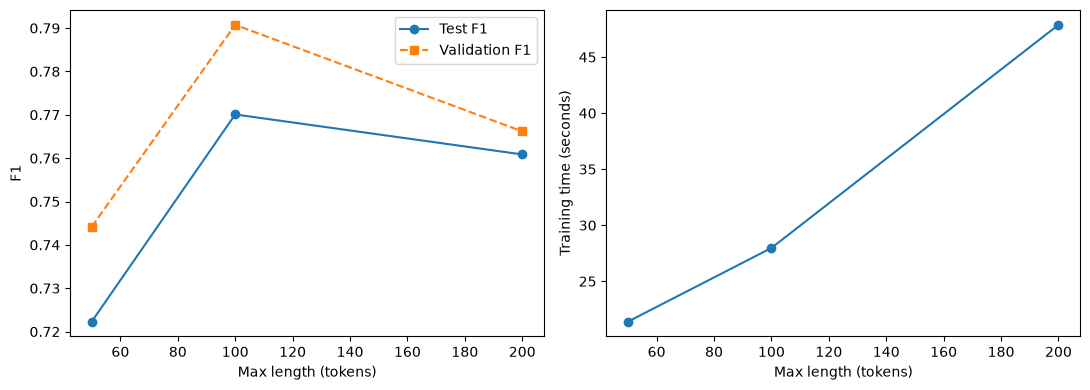

In [8]:
# 20. Experiment 5: fixed RNN length experiment, validation loss, test F1, memory and plots.
history_table=pd.DataFrame(histories)
history_table.to_csv(OUT/'learning_history.csv',index=False)
pd.DataFrame(runs.values()).to_csv(OUT/'locked_run_configs.csv',index=False)
length_results=pd.DataFrame([result_records[f'rnn_{length}'] for length in [50,100,200]])
length_results=length_results.merge(retention.loc[retention.split.eq('test')],
    on='max_length',validate='one_to_one').sort_values('max_length')
length_results.to_csv(OUT/'sequence_length_results.csv',index=False)
display(length_results[['model','max_length','percent_tokens_retained','training_time_seconds',
    'validation_loss','accuracy','f1','cuda_peak_allocated_mb','process_rss_sampled_peak_mb']])
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].plot(length_results.max_length,length_results.f1,'o-',label='Test F1')
axes[0].plot(length_results.max_length,length_results.validation_f1,'s--',label='Validation F1')
axes[0].set(xlabel='Max length (tokens)',ylabel='F1'); axes[0].legend()
axes[1].plot(length_results.max_length,length_results.training_time_seconds,'o-')
axes[1].set(xlabel='Max length (tokens)',ylabel='Training time (seconds)')
fig.tight_layout();fig.savefig(OUT/'sequence_length_experiment.png',dpi=160);plt.show()

In [9]:
# 21. Controlled sentiment-cue position probes; numeric outputs only.
probe_rows = []
filler = ['the','movie','contains','scenes','with','people','in','different','places','and','moments']
for total_length in [40,100,200]:
    for cue in ['excellent','terrible']:
        for position, index in [('beginning',2),('middle',total_length//2),('end',total_length-3)]:
            tokens = (filler*((total_length//len(filler))+1))[:total_length-1]
            tokens.insert(index,cue)
            probe_rows.append(dict(probe_id=f'{total_length}_{cue}_{position}',text=' '.join(tokens),
                cue=cue,cue_position=position,cue_index_zero_based=index,total_tokens=len(tokens)))
probes = pd.DataFrame(probe_rows)
probe_outputs = []
for name,record in runs.items():
    model = load_run(record,DEVICE)
    probs = predict_token_lists(model,[tokenize(t) for t in probes.text],vocab,record['max_length'],DEVICE)
    for row,prob in zip(probes.to_dict('records'),probs):
        probe_outputs.append(dict(**row,model=name,max_length=record['max_length'],
            cue_retained=row['cue_index_zero_based']<record['max_length'],
            positive_probability=float(prob),predicted_label=int(prob>=.5)))
    del model
long_range = pd.DataFrame(probe_outputs)
long_range.to_csv(OUT / 'long_range_position_probes.csv',index=False)
display(long_range[['probe_id','model','cue_index_zero_based','max_length','cue_retained','positive_probability','predicted_label']])

,probe_id,model,cue_index_zero_based,max_length,cue_retained,positive_probability,predicted_label
0,40_excellent_beginning,rnn_50,2,50,True,0.834954,1
1,40_excellent_middle,rnn_50,20,50,True,0.835872,1
2,40_excellent_end,rnn_50,37,50,True,0.887777,1
3,40_terrible_beginning,rnn_50,2,50,True,0.809833,1
4,40_terrible_middle,rnn_50,20,50,True,0.810743,1
...,...,...,...,...,...,...,...
85,200_excellent_middle,gru_100,100,100,False,0.983601,1
86,200_excellent_end,gru_100,197,100,False,0.983601,1
87,200_terrible_beginning,gru_100,2,100,True,0.987449,1
88,200_terrible_middle,gru_100,100,100,False,0.983601,1


,model,parameters,epochs,selected_epoch,max_length,vocabulary_size,training_time_seconds,accuracy,precision,recall,f1,f1_macro,tn,fp,fn,tp
0,rnn_50,1288385,6.0,2.0,50.0,20000,21.396361,0.734306,0.761454,0.686971,0.722298,0.733808,9593,2671,3885,8526
1,rnn_100,1288385,6.0,3.0,100.0,20000,27.971592,0.781398,0.817540,0.727822,0.770077,0.780867,10248,2016,3378,9033
2,rnn_200,1288385,6.0,3.0,200.0,20000,47.877656,0.785167,0.864391,0.679478,0.760861,0.782925,10941,1323,3978,8433
3,tfidf_lr,20001,NaN,NaN,NaN,20000,5.325121,0.889970,0.887716,0.894368,0.891030,0.889959,10860,1404,1311,11100
4,lstm_100,1313345,6.0,3.0,100.0,20000,25.207650,0.805917,0.822529,0.783096,0.802328,0.805853,10167,2097,2692,9719
5,gru_100,1305025,6.0,2.0,100.0,20000,13.000273,0.806687,0.821185,0.787044,0.803752,0.806644,10137,2127,2643,9768


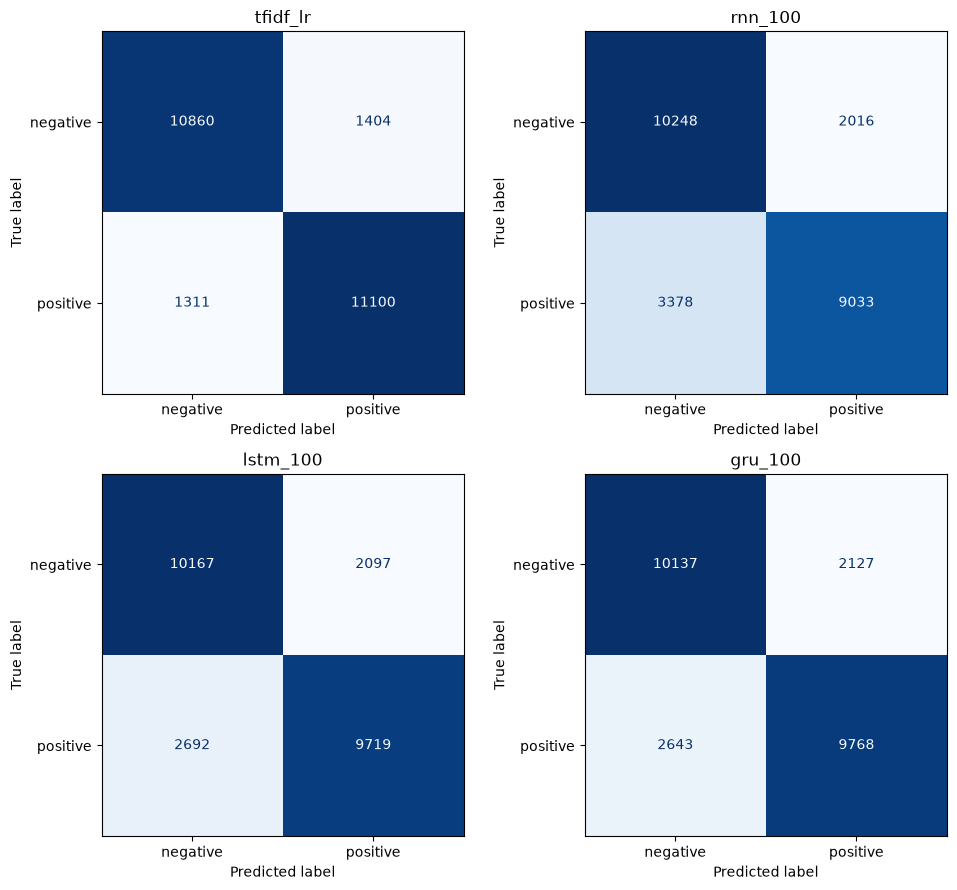

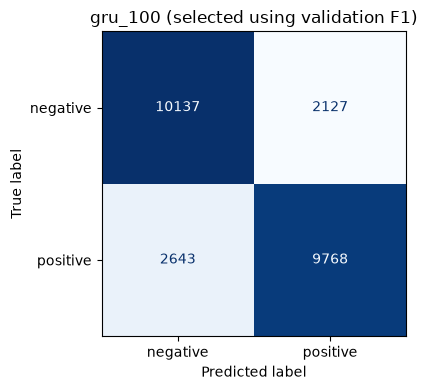

In [10]:
# 22. Final test metrics, parameter counts, computational costs and confusion matrices.
results=pd.DataFrame(result_records.values())
results.to_csv(BASE/'results.csv',index=False)
display(results[['model','parameters','epochs','selected_epoch','max_length','vocabulary_size',
                 'training_time_seconds','accuracy','precision','recall','f1','f1_macro','tn','fp','fn','tp']])
main_names = ['tfidf_lr','rnn_100','lstm_100','gru_100']
results.loc[results.model.isin(main_names)].to_csv(OUT / 'all_main_models_test_comparison.csv',index=False)
fig,axes = plt.subplots(2,2,figsize=(10,9))
per_class_rows = []
for ax,name in zip(axes.flat,main_names):
    table = prediction_tables[name]
    cm = confusion_matrix(table.true_label,table.predicted_label,labels=[0,1])
    ConfusionMatrixDisplay(cm,display_labels=['negative','positive']).plot(ax=ax,colorbar=False,cmap='Blues',values_format='d')
    ax.set_title(name)
    p,r,f,support = precision_recall_fscore_support(table.true_label,table.predicted_label,labels=[0,1],zero_division=0)
    per_class_rows.extend(dict(model=name,label=label,precision=p[label],recall=r[label],f1=f[label],support=int(support[label])) for label in [0,1])
fig.tight_layout(); fig.savefig(OUT / 'confusion_matrices_comparison.png',dpi=160); plt.show()
primary_predictions = prediction_tables[PRIMARY_NAME]
fig,ax = plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay.from_predictions(primary_predictions.true_label,primary_predictions.predicted_label,
    labels=[0,1],display_labels=['negative','positive'],colorbar=False,cmap='Blues',ax=ax,values_format='d')
ax.set_title(PRIMARY_NAME+' (selected using validation F1)')
fig.tight_layout(); fig.savefig(BASE / 'confusion_matrix.png',dpi=160); plt.show()
pd.DataFrame(per_class_rows).to_csv(OUT / 'per_class_metrics.csv',index=False)

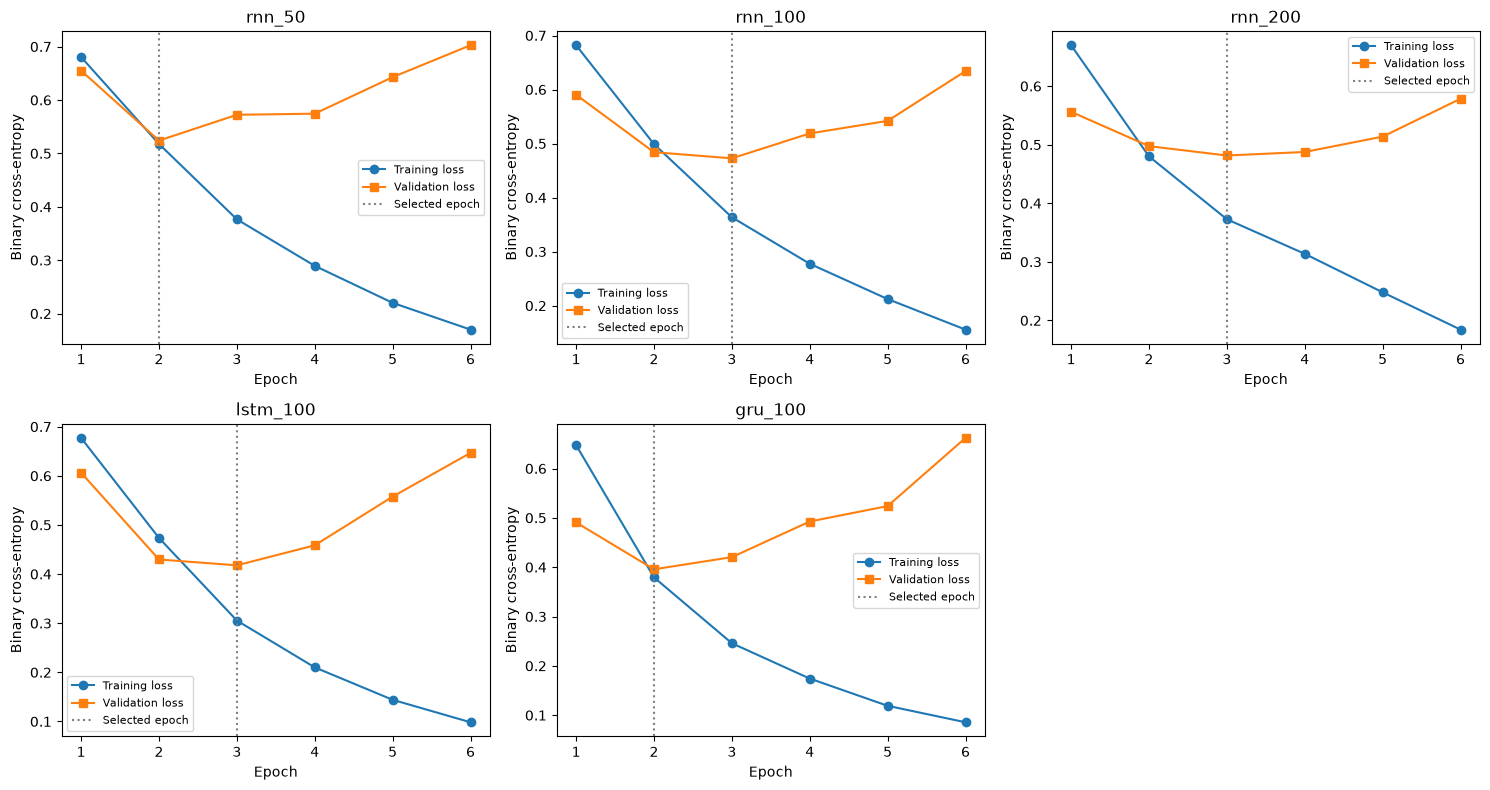

,model,epoch,train_loss,validation_loss,validation_f1,mean_preclip_gradient_norm,training_seconds,validation_seconds
0,rnn_50,1,0.680494,0.655185,0.581564,0.413938,5.990152,0.321654
1,rnn_50,2,0.517758,0.524061,0.744167,2.774031,3.940363,0.347708
2,rnn_50,3,0.376567,0.572346,0.747124,3.320250,3.239672,0.269692
3,rnn_50,4,0.289476,0.574454,0.765292,3.002611,2.291025,0.255850
4,rnn_50,5,0.220153,0.642856,0.747587,3.540666,2.366932,0.286104
5,rnn_50,6,0.170030,0.702661,0.753816,3.023666,3.568217,0.423269
6,rnn_100,1,0.682023,0.590388,0.697494,0.560292,4.458969,0.359181
7,rnn_100,2,0.498956,0.484057,0.794106,3.708647,3.680309,0.531030
8,rnn_100,3,0.363603,0.472643,0.790746,3.888514,3.632307,0.492721
9,rnn_100,4,0.277541,0.518751,0.778830,4.074003,5.002920,0.586395


In [11]:
# 23. All training/validation loss curves, including every epoch and selected checkpoint.
fig,axes = plt.subplots(2,3,figsize=(15,8))
for ax,(name,record) in zip(axes.flat,runs.items()):
    h = history_table.loc[history_table.model.eq(name)]
    ax.plot(h.epoch,h.train_loss,'o-',label='Training loss')
    ax.plot(h.epoch,h.validation_loss,'s-',label='Validation loss')
    ax.axvline(record['selected_epoch'],linestyle=':',color='gray',label='Selected epoch')
    ax.set(title=name,xlabel='Epoch',ylabel='Binary cross-entropy')
    ax.set_xticks(h.epoch); ax.legend(fontsize=8)
for ax in axes.flat[len(runs):]:
    ax.set_visible(False)
fig.tight_layout(); fig.savefig(BASE / 'learning_curves.png',dpi=160); plt.show()
display(history_table)

In [12]:
# 24. Correct/incorrect candidate pool and unannotated six-example table.
pool = primary_predictions.copy()
pool['model'] = PRIMARY_NAME
pool['visible_prefix'] = [' '.join(t[:MAIN_LENGTH]) for t in test.tokens]
pool['discarded_suffix'] = [' '.join(t[MAIN_LENGTH:]) for t in test.tokens]
pool['unknown_tokens_in_prefix'] = [sum(t not in vocab for t in tokens[:MAIN_LENGTH]) for tokens in test.tokens]
pool['truncated'] = pool.original_tokens.gt(MAIN_LENGTH)
pool.to_csv(OUT / 'error_analysis_candidates.csv',index=False)
six = pd.concat([pool.loc[pool.correct].head(3),pool.loc[~pool.correct].head(3)],ignore_index=True)
assert len(six)==6 and six.correct.sum()==3
six.to_csv(OUT / 'six_examples_unannotated.csv',index=False)
display(six[['sample_id','true_label','predicted_label','positive_probability','correct',
             'original_tokens','retained_tokens','truncated','text']])

,sample_id,true_label,predicted_label,positive_probability,correct,original_tokens,retained_tokens,truncated,text
0,test:0,0,0,0.084503,True,240,100,True,"I love sci-fi and am willing to put up with a lot. Sci-fi movies/TV are usually underfunded, under-appreciated and m..."
1,test:1,0,0,0.183113,True,214,100,True,"Worth the entertainment value of a rental, especially if you like action movies. This one features the usual car cha..."
2,test:2,0,0,0.038236,True,134,100,True,its a totally average film with a few semi-alright action sequences that make the plot seem a little better and remi...
3,test:3,0,1,0.674820,False,355,100,True,STAR RATING: ***** Saturday Night **** Friday Night *** Friday Morning ** Sunday Night * Monday Morning <br /><br />...
4,test:4,0,1,0.699207,False,134,100,True,"First off let me say, If you haven't enjoyed a Van Damme movie since bloodsport, you probably will not like this mov..."
5,test:6,0,1,0.705430,False,292,100,True,Isaac Florentine has made some of the best western Martial Arts action movies ever produced. In particular US Seals ...


In [13]:
# 25. LAB04 comparison data and direct order-sensitivity measurements (no explanation).
historical = pd.read_csv(BASE / 'data' / 'lab04_results.csv')
historical = historical.loc[historical.model.isin(['tfidf_unigram_lr','average_word2vec_lr'])].copy()
historical['run_source'] = 'LAB04 historical; same sample IDs/splits; historical training time'
current = results.loc[results.model.isin(main_names)].copy()
current['run_source'] = 'LAB05 current run'
comparison = pd.concat([historical,current],ignore_index=True)
comparison.to_csv(OUT / 'lab04_lab05_comparison.csv',index=False)
display(comparison[['model','run_source','training_time_seconds','accuracy','precision','recall','f1']])

additional_probes,additional_ablation=order_diagnostics(['lstm_100','gru_100'])
order_table=pd.concat([baseline_order_probes,additional_probes],ignore_index=True)
order_ablation=pd.concat([baseline_order_ablation,additional_ablation],ignore_index=True)
order_table.to_csv(OUT/'word_order_probes.csv',index=False)
order_ablation.to_csv(OUT/'word_order_ablation.csv',index=False)
display(order_table,order_ablation)

,model,run_source,training_time_seconds,accuracy,precision,recall,f1
0,tfidf_unigram_lr,LAB04 historical; same sample IDs/splits; historical training time,8.548688,0.889970,0.887716,0.894368,0.891030
1,average_word2vec_lr,LAB04 historical; same sample IDs/splits; historical training time,473.918970,0.859939,0.866738,0.852631,0.859626
2,rnn_100,LAB05 current run,27.971592,0.781398,0.817540,0.727822,0.770077
3,tfidf_lr,LAB05 current run,5.325121,0.889970,0.887716,0.894368,0.891030
4,lstm_100,LAB05 current run,25.207650,0.805917,0.822529,0.783096,0.802328
5,gru_100,LAB05 current run,13.000273,0.806687,0.821185,0.787044,0.803752


,pair,model,text_a,text_b,probability_a,probability_b,absolute_probability_delta,vector_l2_delta
0,0,tfidf_lr,dog bites man,man bites dog,0.491561,0.491561,0.000000,0.000000
1,1,tfidf_lr,this movie is good,this movie is not good,0.706186,0.410895,0.295291,0.474262
2,2,tfidf_lr,good not bad,bad not good,0.004961,0.004961,0.000000,0.000000
3,3,tfidf_lr,i expected bad but it was good,i expected good but it was bad,0.070472,0.070472,0.000000,0.000000
4,0,rnn_100,dog bites man,man bites dog,0.509952,0.494287,0.015665,0.901787
5,1,rnn_100,this movie is good,this movie is not good,0.496257,0.389490,0.106768,0.829241
6,2,rnn_100,good not bad,bad not good,0.106565,0.160377,0.053813,1.271390
7,3,rnn_100,i expected bad but it was good,i expected good but it was bad,0.231484,0.194219,0.037265,1.222919
8,0,lstm_100,dog bites man,man bites dog,0.506357,0.500181,0.006176,0.165938
9,1,lstm_100,this movie is good,this movie is not good,0.573943,0.511335,0.062608,0.206352


,model,split,samples,retained_prefix_tokens,original_f1,shuffled_f1,mean_absolute_probability_delta,changed_class_count
0,tfidf_lr,test,24675,100,0.829910,0.829910,0.000000,0
1,rnn_100,test,24675,100,0.770077,0.768688,0.115224,2433
2,lstm_100,test,24675,100,0.802328,0.802543,0.036503,663
3,gru_100,test,24675,100,0.803752,0.806536,0.036204,660


In [14]:
# 26. Complete LSTM/GRU application, four input types, and numeric UNK perturbations.
application_inputs = [
    ('short','I really enjoyed this movie.'),
    ('long', ' '.join(['The movie follows several characters through a series of events in different places.']*16)
        + ' Despite the slow beginning, the final scenes and performances were wonderful.'),
    ('negation','I did not enjoy this movie. It was not good.'),
    ('contrast','I thought the movie would be terrible, but it was surprisingly good.')]
application_record = runs[APPLICATION_NAME]
application_model = load_run(application_record,DEVICE)
application_rows, perturbation_rows = [],[]
for kind,text in application_inputs:
    tokens = tokenize(text)
    length = application_record['max_length']
    probability = float(predict_token_lists(application_model,[tokens],vocab,length,DEVICE)[0])
    retained = tokens[:length]
    application_rows.append(dict(input_type=kind,text=text,model=APPLICATION_NAME,
        original_tokens=len(tokens),retained_tokens=len(retained),truncated=len(tokens)>length,
        visible_prefix=' '.join(retained),discarded_suffix=' '.join(tokens[length:]),
        positive_probability=probability,predicted_label=int(probability>=.5),
        sentiment='Positive' if probability>=.5 else 'Negative'))
    for start in range(0,len(retained),5):
        end = min(start+5,len(retained))
        perturbed = retained.copy()
        perturbed[start:end] = ['<UNK>']*(end-start)
        after = float(predict_token_lists(application_model,[perturbed],vocab,length,DEVICE)[0])
        perturbation_rows.append(dict(input_type=kind,start_token=start,end_token_exclusive=end,
            replaced_span=' '.join(retained[start:end]),base_positive_probability=probability,
            perturbed_positive_probability=after,probability_delta=probability-after))
application_table = pd.DataFrame(application_rows)
application_table.to_csv(OUT / 'application_predictions.csv',index=False)
perturbations = pd.DataFrame(perturbation_rows)
perturbations.to_csv(OUT / 'application_span_perturbations.csv',index=False)
display(application_table)
display(perturbations)
del application_model

,input_type,text,model,original_tokens,retained_tokens,truncated,visible_prefix,discarded_suffix,positive_probability,predicted_label,sentiment
0,short,I really enjoyed this movie.,gru_100,5,5,False,i really enjoyed this movie,,0.685557,1,Positive
1,long,The movie follows several characters through a series of events in different places. The movie follows several chara...,gru_100,219,100,True,the movie follows several characters through a series of events in different places the movie follows several charac...,events in different places the movie follows several characters through a series of events in different places the m...,0.963814,1,Positive
2,negation,I did not enjoy this movie. It was not good.,gru_100,10,10,False,i did not enjoy this movie it was not good,,0.609698,1,Positive
3,contrast,"I thought the movie would be terrible, but it was surprisingly good.",gru_100,12,12,False,i thought the movie would be terrible but it was surprisingly good,,0.344230,0,Negative


,input_type,start_token,end_token_exclusive,replaced_span,base_positive_probability,perturbed_positive_probability,probability_delta
0,short,0,5,i really enjoyed this movie,0.685557,0.389439,0.296117
1,long,0,5,the movie follows several characters,0.963814,0.963242,0.000572
2,long,5,10,through a series of events,0.963814,0.963299,0.000514
3,long,10,15,in different places the movie,0.963814,0.962672,0.001142
4,long,15,20,follows several characters through a,0.963814,0.963416,0.000397
5,long,20,25,series of events in different,0.963814,0.962407,0.001407
6,long,25,30,places the movie follows several,0.963814,0.962828,0.000985
7,long,30,35,characters through a series of,0.963814,0.963262,0.000551
8,long,35,40,events in different places the,0.963814,0.962147,0.001667
9,long,40,45,movie follows several characters through,0.963814,0.963362,0.000452
